Nome: tiago oliveira lima

Matrícula: 564988

# 1. Você joga uma moeda 10 vezes, observando 8 vezes o resultado cara (X = 1). Considerando um modelo Beta-Bernoulli: 

## Calcule a probabilidade θ dessa moeda dar cara (X = 1) considerando uma estimação: 


In [30]:
N = 10
k = 8

## ML(maximum likehood)

--- Solução Analítica ---
Estimação ML (Analítica) para theta: 0.80

--- Solução via Gradiente Descendente ---
Estimação ML (Iterativa) para theta: 0.8000


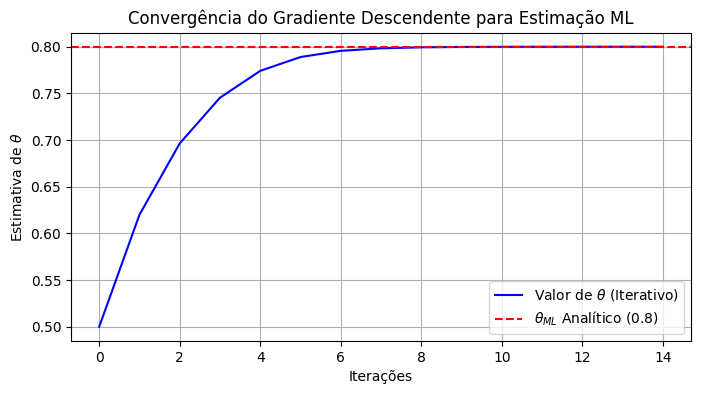

In [31]:
import numpy as np
import matplotlib.pyplot as plt


# ==========================================
# 1. SOLUÇÃO ANALÍTICA
# ==========================================

# ==============
#  EXPLICAÇÃO
# ==============
# theta = ARG MAX L(theta|X) = ARG MAX P(X|theta)

# L(theta|X) = theta^k * (1-theta)^(N-k)

# aplicando log na verossimilhança:
# l(theta) = k * log(theta) + (N-k) * log(1-theta)

# Derivando:
# l'(theta) = k/theta - (N-k)/(1-theta) = 0

# Assim:
# theta = k/N

# Aqui não usamos o beta, pois a máxima verossimilhança não assume uma priori sobre a moeda.

theta_ml_analitico = k / N

print(f"--- Solução Analítica ---")
print(f"Estimação ML (Analítica) para theta: {theta_ml_analitico:.2f}")

# ==========================================
# 2. SOLUÇÃO ITERATIVA (Gradiente Descendente)
# ==========================================

def gradiente_nll(theta, k, N):
    # Evitando divisão por zero nos limites
    theta = np.clip(theta, 1e-7, 1 - 1e-7)
    # Derivada de J(theta) = - [k*log(theta) + (N-k)*log(1-theta)]
    grad = - (k / theta) + ((N - k) / (1 - theta))
    return grad

taxa_aprendizado = 0.01  
iteracoes = 15
theta_gd = 0.5           # Começando assumindo que a moeda é honesta
historico_theta = []

for t in range(iteracoes):
    historico_theta.append(theta_gd)
    grad = gradiente_nll(theta_gd, k, N)
    
    # theta(t) = theta(t-1) - alpha * gradiente
    theta_gd = theta_gd - taxa_aprendizado * grad
    
    # Mantendo theta no domínio de probabilidade válido [0, 1]
    theta_gd = np.clip(theta_gd, 1e-7, 1 - 1e-7)

print(f"\n--- Solução via Gradiente Descendente ---")
print(f"Estimação ML (Iterativa) para theta: {theta_gd:.4f}")

# ==========================================
# 3. VISUALIZAÇÃO DA CONVERGÊNCIA
# ==========================================
plt.figure(figsize=(8, 4))
plt.plot(historico_theta, label='Valor de $\\theta$ (Iterativo)', color='blue')
plt.axhline(y=theta_ml_analitico, color='red', linestyle='--', label='$\\theta_{ML}$ Analítico (0.8)')
plt.title("Convergência do Gradiente Descendente para Estimação ML")
plt.xlabel("Iterações")
plt.ylabel("Estimativa de $\\theta$")
plt.legend()
plt.grid(True)
plt.show()


## MAP

Estimativa ML Pura (k/N): 0.8000
Solução Analítica MAP: 0.7500
Solução Iterativa MAP (GD): 0.7500


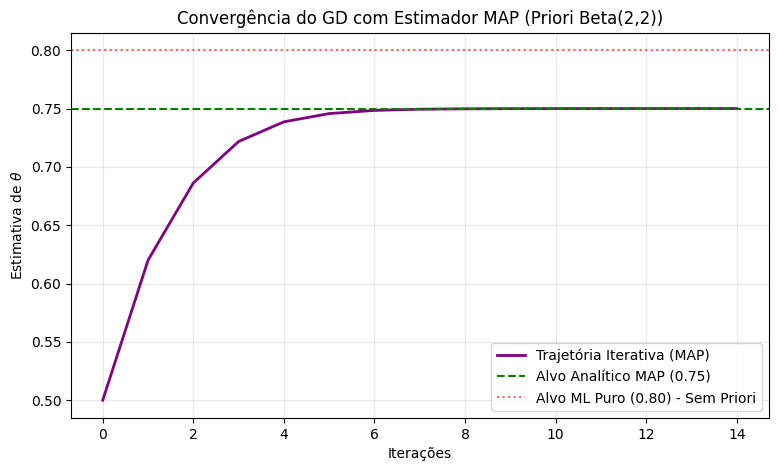

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Hiperparâmetros da Priori Beta(a, b)
# a=2, b=2 cria uma leve crença de que a moeda é honesta (pico em 0.5)
a = 2
b = 2

# ==========================================
# 2. SOLUÇÃO ANALÍTICA 
# ==========================================
# Solução fechada MAP para modelo Beta-Bernoulli conjugado
theta_map_analitico = (k + a - 1) / (N + a + b - 2)


# ==========================================
# 3. FUNÇÕES DO OTIMIZADOR MAP
# ==========================================
def gradiente_map(theta, sucessos, total, alpha_prior, beta_prior):
    theta = np.clip(theta, 1e-10, 1 - 1e-10)
    
    grad_verossimilhanca = -(sucessos / theta) + ((total - sucessos) / (1 - theta))
    grad_priori = -((alpha_prior - 1) / theta) + ((beta_prior - 1) / (1 - theta))
    
    return grad_verossimilhanca + grad_priori


# ==========================================
# 4. OTIMIZAÇÃO ITERATIVA (GRADIENTE DESCENDENTE)
# ==========================================
taxa_aprendizado = 0.01  
iteracoes = 15
theta_gd = 0.5           # Chute inicial

historico_theta_map = []

for epoca in range(iteracoes):
    historico_theta_map.append(theta_gd)
    
    grad = gradiente_map(theta_gd, k, N, a, b)
    theta_gd = theta_gd - (taxa_aprendizado * grad)
    
    # Mantém a estabilidade numérica limitando a probabilidade
    theta_gd = np.clip(theta_gd, 1e-10, 1 - 1e-10)

print(f"Estimativa ML Pura (k/N): {k/N:.4f}")
print(f"Solução Analítica MAP: {theta_map_analitico:.4f}")
print(f"Solução Iterativa MAP (GD): {theta_gd:.4f}")

# ==========================================
# 5. VISUALIZAÇÃO DO EFEITO REGULARIZADOR
# ==========================================
plt.figure(figsize=(9, 5))
plt.plot(historico_theta_map, label='Trajetória Iterativa (MAP)', color='purple', linewidth=2)
plt.axhline(y=theta_map_analitico, color='green', linestyle='--', label=f'Alvo Analítico MAP ({theta_map_analitico:.2f})')
plt.axhline(y=k/N, color='red', linestyle=':', label=f'Alvo ML Puro ({k/N:.2f}) - Sem Priori', alpha=0.6)

plt.title("Convergência do GD com Estimador MAP (Priori Beta(2,2))")
plt.xlabel("Iterações")
plt.ylabel("Estimativa de $\\theta$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## média da posteriori (solução Bayesiana)

--- Solução Analítica Bayesiana ---
Média da Posteriori Exata: 0.7143

--- Solução via Monte Carlo ---
Média da Posteriori (Estimada via MCMC): 0.7141


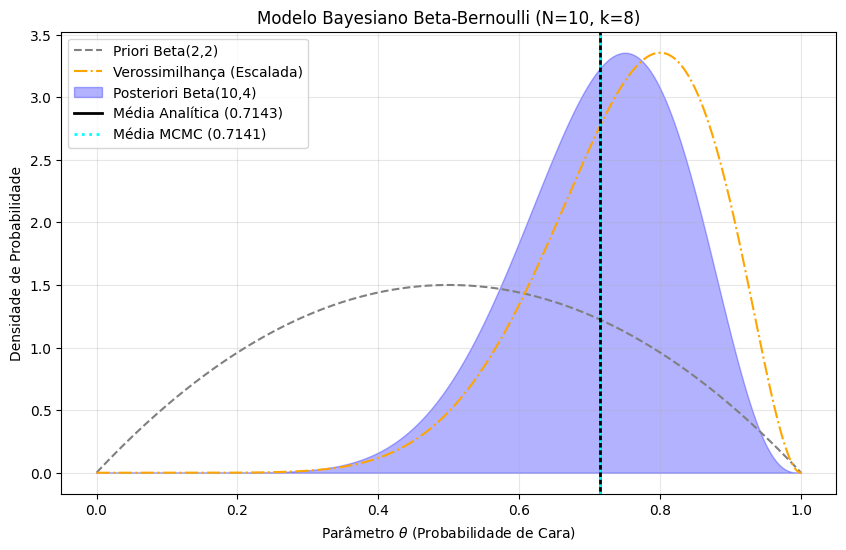

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Hiperparâmetros da Priori Beta(a, b)
a = 2
b = 2

# Os parâmetros atualizados da Posteriori (Evidência + Priori)
alpha_post = k + a
beta_post = N - k + b

# ==========================================
# 1. SOLUÇÃO ANALÍTICA 
# ==========================================
# E[theta] = alpha / (alpha + beta)
theta_bayes_analitico = alpha_post / (alpha_post + beta_post)

print(f"--- Solução Analítica Bayesiana ---")
print(f"Média da Posteriori Exata: {theta_bayes_analitico:.4f}")

# ==========================================
# 2. SOLUÇÃO NUMÉRICA (Amostragem de Monte Carlo)
# ==========================================
# Usando amostragem estocástica.
num_amostras = 100000

# Extraindo amostras diretamente da posteriori
amostras_mcmc = np.random.beta(alpha_post, beta_post, num_amostras)

# A aproximação de Monte Carlo para a integral é a média empírica
theta_bayes_mcmc = np.mean(amostras_mcmc)

print(f"\n--- Solução via Monte Carlo ---")
print(f"Média da Posteriori (Estimada via MCMC): {theta_bayes_mcmc:.4f}")

# ==========================================
# 3. PLOTAGEM EXCLUSIVA DO MODELO BAYESIANO
# ==========================================
x = np.linspace(0, 1, 500)

# Função da Priori Beta(a,b)
pdf_priori = beta.pdf(x, a, b)

# Função da Posteriori Beta(k+a, N-k+b)
pdf_posteriori = beta.pdf(x, alpha_post, beta_post)

# Verossimilhança 
# L(theta) = theta^k * (1-theta)^(N-k)
verossimilhanca = (x**k) * ((1-x)**(N-k))
verossimilhanca_escalada = verossimilhanca * (max(pdf_posteriori) / max(verossimilhanca))

# Renderização do Gráfico
plt.figure(figsize=(10, 6))

# A Tríade Bayesiana (Priori, Verossimilhança e Posteriori)
plt.plot(x, pdf_priori, label=f'Priori Beta({a},{b})', color='gray', linestyle='--')
plt.plot(x, verossimilhanca_escalada, label='Verossimilhança (Escalada)', color='orange', linestyle='-.')
plt.fill_between(x, pdf_posteriori, color='blue', alpha=0.3, label=f'Posteriori Beta({alpha_post},{beta_post})')

# Marcando exclusivamente as Médias Bayesianas calculadas
plt.axvline(theta_bayes_analitico, color='black', linestyle='-', linewidth=2, label=f'Média Analítica ({theta_bayes_analitico:.4f})')
plt.axvline(theta_bayes_mcmc, color='cyan', linestyle=':', linewidth=2, label=f'Média MCMC ({theta_bayes_mcmc:.4f})')

plt.title(f"Modelo Bayesiano Beta-Bernoulli (N={N}, k={k})")
plt.xlabel("Parâmetro $\\theta$ (Probabilidade de Cara)")
plt.ylabel("Densidade de Probabilidade")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Plote as distribuições (priori e posteriori) e a verossimilhança desse modelo considerando as priori p(θ) = Beta(θ|a = 1, b = 1) e p(θ) = Beta(θ|a = 2, b = 2).

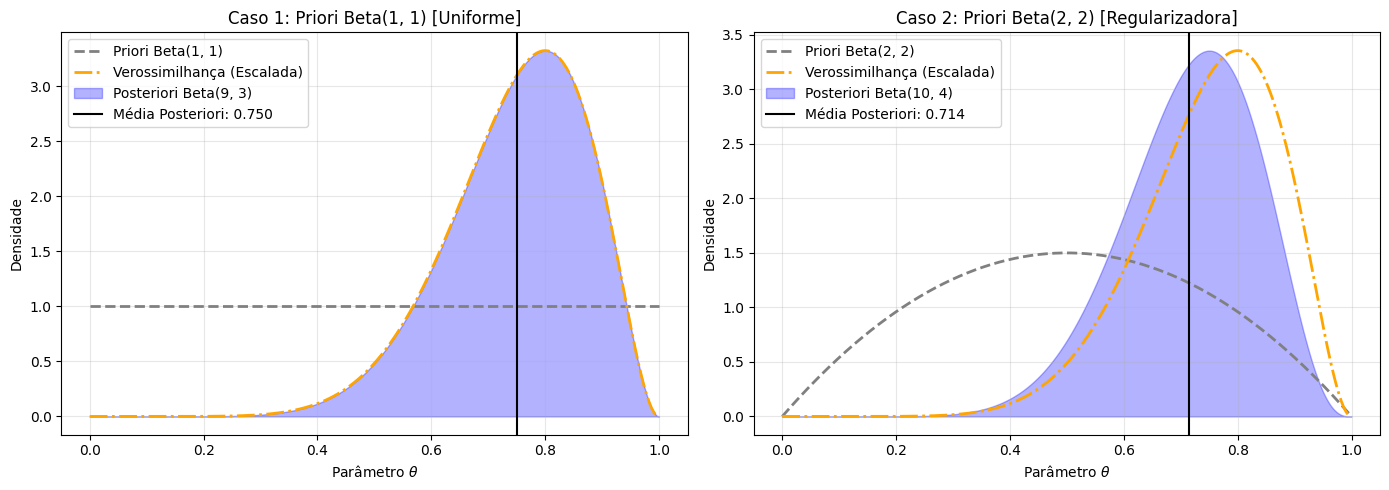

In [34]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# Espaço contínuo do parâmetro latente theta
x = np.linspace(0, 1, 500)

# Verossimilhança: L(theta) = theta^k * (1-theta)^(N-k)
verossimilhanca = (x**k) * ((1-x)**(N-k))

# ==========================================
# 1. CONFIGURAÇÃO DAS PRIORIS
# ==========================================
prioris = [
    {'a': 1, 'b': 1, 'titulo': 'Caso 1: Priori Beta(1, 1) [Uniforme]'},
    {'a': 2, 'b': 2, 'titulo': 'Caso 2: Priori Beta(2, 2) [Regularizadora]'}
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ==========================================
# 2. MOTOR DE RENDERIZAÇÃO BAYESIANA
# ==========================================
for ax, params in zip(axes, prioris):
    a = params['a']
    b = params['b']
    
    # Atualização Analítica Conjugada (Evidência + Priori)
    alpha_post = k + a
    beta_post = N - k + b
    
    # Geração das PDFs(Probability Density Function)
    pdf_priori = beta.pdf(x, a, b)
    pdf_posteriori = beta.pdf(x, alpha_post, beta_post)
    
    verossimilhanca_escalada = verossimilhanca * (max(pdf_posteriori) / max(verossimilhanca))
    
    # Plotagem 
    ax.plot(x, pdf_priori, label=f'Priori Beta({a}, {b})', color='gray', linestyle='--', linewidth=2)
    ax.plot(x, verossimilhanca_escalada, label='Verossimilhança (Escalada)', color='orange', linestyle='-.', linewidth=2)
    ax.fill_between(x, pdf_posteriori, color='blue', alpha=0.3, label=f'Posteriori Beta({alpha_post}, {beta_post})')
    
    # Marcação do Centro de Massa (Média da Posteriori)
    media_bayes = alpha_post / (alpha_post + beta_post)
    ax.axvline(media_bayes, color='black', linestyle='-', linewidth=1.5, label=f'Média Posteriori: {media_bayes:.3f}')
    
    # Estética do Subplot
    ax.set_title(params['titulo'])
    ax.set_xlabel('Parâmetro $\\theta$')
    ax.set_ylabel('Densidade')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Modelo de Bernoulli Naive Bayes Bayesiano

In [35]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score

# 1. Carregamento e Preparação dos Dados
data = pd.read_csv("cleaned_reviews.csv").dropna()
y_raw = data.iloc[:, 0].values

# Converte a coluna Arrow/pandas para um ndarray comum
X_raw = data.iloc[:, 1].astype(str).to_numpy()

# Codificação das classes
y = LabelEncoder().fit_transform(y_raw)

# 2. Configuração do Experimento
repeticoes = 20
tamanho_treino = 1000

# Mapeamento estrito das Prioris Beta(a,b) para o hiperparâmetro alpha
prioris = {
    "Beta(1.0, 1.0)": 1.0,
    "Beta(0.5, 0.5)": 0.5,
    "Beta(2.0, 2.0)": 2.0
}

resultados_acuracia = {nome: [] for nome in prioris.keys()}

# 3. Execução das Repetições Aleatórias
for i in range(repeticoes):
    # Separação aleatória garantindo exatamente 1000 instâncias de treinamento
    X_train_raw, X_test_raw, y_train, y_test = train_test_split(
        X_raw, y, train_size=tamanho_treino, random_state=i
    )
    
    # O Vocabulário deve ser ajustado somente no conjunto de treinamento
    encoder = CountVectorizer(binary=True).fit(X_train_raw)
    
    X_train_bow = encoder.transform(X_train_raw)
    X_test_bow = encoder.transform(X_test_raw)
    
    # Avaliando cada uma das prioris solicitadas
    for nome_prior, alpha_val in prioris.items():
        modelo_nb = BernoulliNB(alpha=alpha_val)
        modelo_nb.fit(X_train_bow, y_train)
        
        y_pred = modelo_nb.predict(X_test_bow)
        acc = accuracy_score(y_test, y_pred)
        
        resultados_acuracia[nome_prior].append(acc)

# 4. Cálculo e Exibição das Estatísticas
print("--- RESULTADOS DO EXPERIMENTO (20 RODADAS) ---\n")

for nome_prior in prioris.keys():
    vetor_acuracias = np.array(resultados_acuracia[nome_prior])
    
    media = np.mean(vetor_acuracias)
    desvio = np.std(vetor_acuracias)
    
    print(f"Priori p(θ) = {nome_prior}:")
    print(f" -> Média da Acurácia: {media:.4f}")
    print(f" -> Desvio Padrão    : {desvio:.4f}\n")

--- RESULTADOS DO EXPERIMENTO (20 RODADAS) ---

Priori p(θ) = Beta(1.0, 1.0):
 -> Média da Acurácia: 0.6785
 -> Desvio Padrão    : 0.0278

Priori p(θ) = Beta(0.5, 0.5):
 -> Média da Acurácia: 0.6561
 -> Desvio Padrão    : 0.0252

Priori p(θ) = Beta(2.0, 2.0):
 -> Média da Acurácia: 0.6901
 -> Desvio Padrão    : 0.0234

